In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import StandardScaler
import umap.umap_ as umap
import os
import matplotlib.pyplot as plt
import glob
from itertools import cycle

2024-08-01 13:49:43.642165: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


PLOT COLORMAPS

In [2]:
# Path to files
l2000_files_path = '/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/theory_2pcf/lhs_2000_0'
param_path = "/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/lhs_2000/lhs_2000_0.csv"

# Load files
l2000_files_names = sorted(glob.glob(f"{l2000_files_path}/id*2pcf.dat"))
l2000_files_full = [np.loadtxt(file) for file in l2000_files_names]

# Parameters
params = pd.read_csv(param_path)
params_list = ['$\Omega_m$','$\sigma_8$','$h$','$w_0$']
Om = params['Om']
S8 = params['sig8']
h = params['h']
w0 = params['w0']
params_values = [Om,S8,h,w0]

l2000_files = []
for i in range(len(l2000_files_full)):
   data = l2000_files_full[i]
   row = [row[1] for row in data]
   l2000_files.append(row)

print("Shape l2000 : ",np.shape(l2000_files))

Shape l2000 :  (2000, 10)


In [3]:
# UMAP
rd_state = 0
umap_2d_full = umap.UMAP(n_components=2, random_state=rd_state)

umap_embedding_2d_full = umap_2d_full.fit_transform(l2000_files)

/net/CLUSTER/VAULT/users/lburon/micromamba/envs/SHEAR2COSMO/lib/python3.11/site-packages/umap/umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


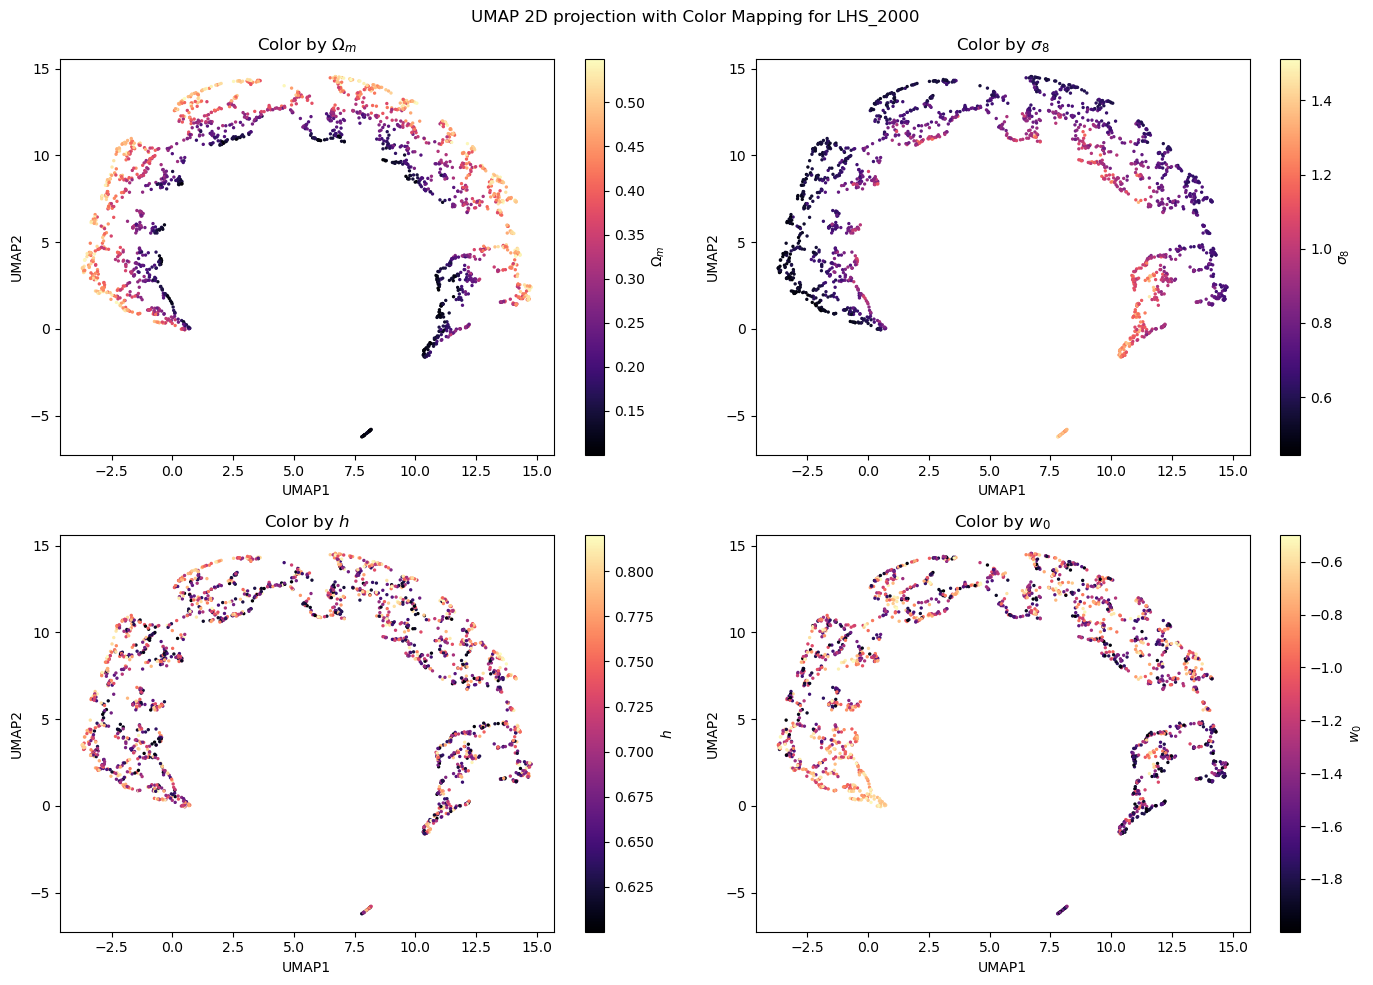

In [4]:
# PLOTS

fig, axs = plt.subplots(2, 2, figsize=(14, 10))

# Plot each subplot
for i, ax in enumerate(axs.flat):
    scatter = ax.scatter(umap_embedding_2d_full[:, 0], umap_embedding_2d_full[:, 1], 
                         c=params_values[i], s=2, alpha=1, cmap='magma')
    ax.set_xlabel(f'UMAP1')
    ax.set_ylabel(f'UMAP2')
    ax.set_title(f'Color by {params_list[i]}')
    cbar = plt.colorbar(scatter, ax=ax)
    cbar.set_label(params_list[i])

plt.suptitle('UMAP 2D projection with Color Mapping for LHS_2000')
plt.tight_layout()
plt.show()